# Lesson 13: Kinetics III: Multi-Step Reactions and Tafel-Slope Diagnostics
The Butler-Volmer equation was built for a single one-electron transfer. Every reaction that motivated this course is a multi-electron reaction: hydrogen evolution takes two, oxygen evolution takes four, and CO$_2$ reduction can take eight or more. This lesson closes that gap, and gives you the diagnostic that most electrocatalysis papers are built on.

Today's topics:
- Elementary steps, the rate determining step, and where a Tafel slope comes from
- Tafel slopes and reaction orders as mechanistic diagnostics, and the limits of both
- Microkinetic models, and what happens when no step is rate determining
- Surface coverage, scaling relations and volcano plots

**Reference:**
- Section 3.5 in *Electrochemical Methods: Fundamentals and Applications*, Allen J. Bard & Larry R. Faulkner.
- Chapters 2 and 3 in *Fundamental Concepts in Heterogeneous Catalysis*, Norskov, Studt, Abild-Pedersen & Bligaard.
---

## Configure Environment

In [1]:
import sys
if '../Resources' not in sys.path:
    sys.path.append('../Resources')     # so that echem.py can be found

import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact, widgets

import echem                            # the shared toolkit for this course
from echem import R, T, F, f, WIDE      # constants and the two-panel figure size
echem.use_style()                       # course-wide graph formatting

# 1. One Electron Is Not Enough

[Lesson 11](L11-Kinetics-I-ButlerVolmer.ipynb) and [Lesson 12](L12-Kinetics-II-Tafel.ipynb) built the Butler-Volmer equation for the generic reaction

$ \large O + e^- \rightleftharpoons R $

and we were careful to say that $n = 1$ throughout. That was not modesty. The derivation genuinely assumes a single electron crosses the interface in a single act, because two electrons arriving simultaneously at one molecule is not something that happens.

So what do we do with a more reaction like water splitting?

$ \large 2H_2O \rightleftharpoons O_2 + 4H^+ + 4e^- $

We chain one-electron steps together. The overall reaction is the sum of all steps; the reaction that actually occurs is a sequence of **elementary steps**, each of which we treat with our electron transfer kinetic theory of choice.

<div class="alert alert-block alert-success">
<b>Elementary step</b>: a single molecular event, involving at most one electron transfer, that cannot be broken down further. The Butler-Volmer equation applies to each elementary step individually.
</div>

One step in the sequence of reactions is assuemd to be slower than the others, effectively setting the rate at which the reaction occurs.

<div class="alert alert-block alert-success">
<b>Rate determining step (RDS)</b>: the elementary step whose rate constant limits the overall reaction rate. Every step before it is treated as being at equilibrium.
</div>

The last stentence for the RDS is where the phys-chem lives. If two electrons have have to be transerred before the slow step happens, the applied potential is doing work on the system twice over before it does work on the RDS barrier. 

# 2. The Hydrogen Evolution Reaction

HER in acid is the cleanest example in the field: two electrons, one adsorbed intermediate, and three plausible mechanisms. Writing $*$ for an empty surface site and $H*$ for an adsorbed hydrogen atom:

$ \large \textbf{Volmer:} \quad H^+ + e^- + * \rightleftharpoons H* $

$ \large \textbf{Heyrovsky:} \quad H* + H^+ + e^- \rightleftharpoons H_2 + * $

$ \large \textbf{Tafel:} \quad 2H* \rightleftharpoons H_2 + 2* $

Every route starts with Volmer. It can then finish either electrochemically (Heyrovsky) or chemically (Tafel). So there are three candidates for the rate determining step, and the experiment has to tell them apart.

<div class="alert alert-block alert-info">
<b>Activity:</b> Before running the cell below, rank the three possibilities.
<br>
Which rate determining step should give the <b>steepest</b> Tafel slope, and which the <b>shallowest</b>? Write your reasoning in one sentence.
<br>
Hint: count how many electrons have already been transferred, at equilibrium, before the slow step happens.
</div>

My prediction:
- Steepest slope: ANSWER
- Shallowest slope: ANSWER
- Because: ANSWER

The slope of a Tafel plot is set by the **apparent transfer coefficient**, which we will write $\alpha_{app}$:

$ \large b = \frac{2.303RT}{\alpha_{app} F} $

For a single one-electron step, $\alpha_{app}$ is just the symmetry factor $\beta$ and $b$ comes out near 118 mV per decade. For a multi-step reaction it also counts the electrons transferred before the RDS:

$ \large \alpha_{app} = n_{prior} + \beta $ &nbsp;&nbsp; (electrochemical RDS)

$ \large \alpha_{app} = n_{prior} $ &nbsp;&nbsp; (chemical RDS, no charge crosses the interface in the slow step)

Where:
- $n_{prior}$: number of electrons transferred in the steps preceding the RDS
- $\beta$: the symmetry factor of the rate determining step, taken as 0.5

#### Where $\alpha_{app}$ comes from

It is valuable to understand how this seemingly trivial simplification comes about. Lets assume that the Heyrovsky step is rate determining. We therefore assume that the Volmer step, which must precede it, is at equilibrium.

If the Volmer is at equilibrium, we can adapt the Nernst equation to describe it:

$ \large \frac{\theta}{1 - \theta} = K e^{-f\eta} $

The surface coverage of H*, $\theta$, can be viewed as two limits (~1 and ~0) and a rapid voltage-induced transition between them. The simplest situations are when the system is operating at one of these two limits.

At low coverage $1 - \theta \approx 1$, so:

$\large \theta \propto e^{-f\eta}$

**The potential has already set the amount of H\* sitting on the surface before the slow step is ever reached.**

The Heyrovsky step then carries its own Butler-Volmer factor, and its rate is proportional to the coverage it has to work with (in practice, we can expand this equation fully using Butler-Volmer or other theories):

$ \large i \propto \theta e^{-\beta f \eta} $

Substituting for $\theta$

$ \large i \propto e^{-f\eta} \cdot e^{-\beta f\eta} = e^{-(1 + \beta) f\eta} $

One full electron of potential dependence is generated by the 1-electron pre-equilibrium, plus the transfer coefficient ($\beta$) of an electron transfer of the RDS. So $\alpha_{app} = 1 + \beta = 1.5$. With $\beta = 0.5$ that is 39 mV per decade.

<div class="alert alert-block alert-info">
<b>Activity:</b> Now build the Tafel-rate-determining case the same way. Two Volmer steps are equilibrated in front of it, and the slow step is $2H* \rightarrow H_2 + 2*$, which is <b>chemical</b>.
<br>
You should arrive at $\alpha_{app} = 2$. Notice that $\beta$ has vanished. Why?
</div>

- Rate of the slow step, in terms of $\theta$: ANSWER
- $\theta$ in terms of $\eta$: ANSWER
- $\beta$ does not appear because: ANSWER

In [2]:
# echem.HER_MECHANISMS holds the apparent transfer coefficient for each case,
# and echem.tafel_slope turns it into a slope in volts per decade.
print(f"{'rate determining step':<28} {'n_prior':>8} {'alpha_app':>10} {'b /mV dec-1':>13}")
for name, alpha_app in echem.HER_MECHANISMS.items():
    n_prior = int(alpha_app - 0.5) if alpha_app % 1 else int(alpha_app)
    print(f'{name:<28} {n_prior:>8} {alpha_app:>10} {1000*echem.tafel_slope(alpha_app):>13.1f}')

rate determining step         n_prior  alpha_app   b /mV dec-1
Volmer rate determining             0        0.5         118.3
Heyrovsky rate determining          1        1.5          39.4
Tafel rate determining              2        2.0          29.6


**118, 39 and 30 mV per decade.** These three numbers, usually quoted as 120, 40 and 30, are the single most cited diagnostic in electrocatalysis. Let us see what they look like.

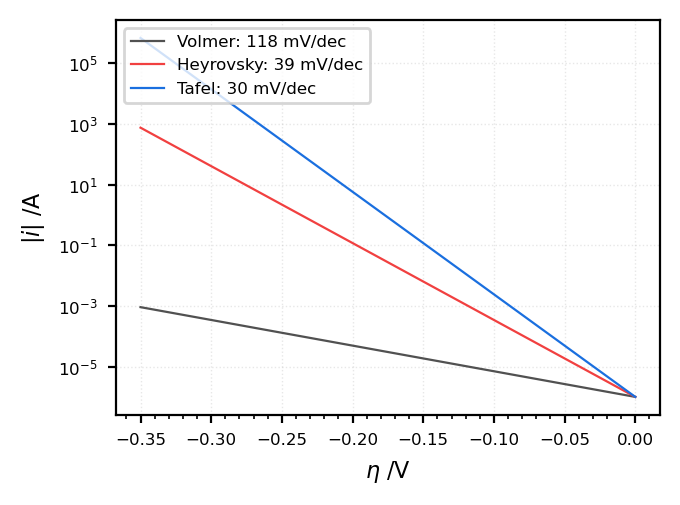

In [3]:
overpotential = np.linspace(-0.35, 0.0, 200)      # V, cathodic
i_0 = 1e-6                                        # A, an arbitrary common starting point

fig = plt.figure()
ax = plt.subplot()
for name, alpha_app in echem.HER_MECHANISMS.items():
    b = echem.tafel_slope(alpha_app)
    current = i_0*np.power(10.0, -overpotential/b)
    ax.plot(overpotential, current, label=f'{name.split(" rate")[0]}: {1000*b:.0f} mV/dec')

ax.set_yscale('log')
ax.set_xlabel(r'$\eta$ /V')
ax.set_ylabel(r'$|i|$ /A')
ax.legend(fontsize=6, loc=2)
fig.savefig('../Workspace/tafel-mechanisms.png')

Hopefully you noticed the ordering, and hopefully it now makes sense: the more electrons that have already been transferred before the slow step, the more leverage the applied potential has, and the **shallower** the slope. Volmer-limited is the steepest because the potential only gets one chance to help.

# 3. What a Tafel Slope Can and Cannot Tell You

<div class="alert alert-block alert-success">
<b>Apparent transfer coefficient</b> ($\alpha_{app}$): the quantity actually obtained from the slope of a Tafel plot. It is <b>not</b> the symmetry factor $\beta$ unless the reaction is a single one-electron transfer.
</div>

This distinction matters more than almost anything else in this lesson. [Lesson 12](L12-Kinetics-II-Tafel.ipynb) introduced $\alpha$ as an empirical measure of the symmetry of two potential energy surfaces, and warned you that it was already a fudge. What you measure on a real catalyst is a different quantity again, and it carries mechanistic information that the symmetry factor never did.

# 4. Reaction Order: The Second Diagnostic

A Tafel slope asks how the current responds to **potential**. Nothing stops us asking how it responds to **concentration** instead.

<div class="alert alert-block alert-success">
<b>Reaction order</b> ($\rho_j$): the slope of $\log i$ against $\log a_j$ for a species $j$, measured at <b>constant potential</b>. For HER in acid the species of interest is H$^+$.
</div>

The approach is the same as for the Tafel slope. Count the protons consumed in the rate determining step, then add the protons consumed in every step equilibrated in front of it.

- **Volmer limited**: one proton in the slow step, nothing before it. $\rho = 1$.
- **Heyrovsky limited**: one proton in the slow step, and one more in the Volmer pre-equilibrium that set $\theta$. $\rho = 2$.
- **Tafel limited**: no proton in the slow step at all, but two sit in the two equilibrated Volmer steps. $\rho = 2$.

In [4]:
# The two diagnostics side by side.  echem.HER_REACTION_ORDERS holds the order
# measured at fixed potential vs SHE; reaction_order_on_rhe converts it.
print(f"{'rate determining step':<28} {'b /mV dec-1':>12} {'rho (SHE)':>10} {'rho (RHE)':>10}")
for name, alpha_app in echem.HER_MECHANISMS.items():
    rho_she = echem.HER_REACTION_ORDERS[name]
    rho_rhe = echem.reaction_order_on_rhe(rho_she, alpha_app)
    print(f'{name:<28} {1000*echem.tafel_slope(alpha_app):>12.1f} {rho_she:>10.1f} {rho_rhe:>10.1f}')

rate determining step         b /mV dec-1  rho (SHE)  rho (RHE)
Volmer rate determining             118.3        1.0        0.5
Heyrovsky rate determining           39.4        2.0        0.5
Tafel rate determining               29.6        2.0        0.0


Read that table across the rows rather than down the columns. The slope separates Tafel from Heyrovsky, and the reaction order separates Volmer from both. **Neither number identifies a mechanism on its own, and the pair very nearly does.**

This is the general shape of a good scientific argument: single decisive measurements rarely exist, and it is much more compelling to combine discrete experiments that operate of different aspects of the system.

<div class="alert alert-block alert-danger">
<b>Check your reference!</b>
<br>
You measure a reaction order by changing the pH. Did you hold the potential fixed against SHE, or the overpotential fixed against RHE?
</div>

Notice the last two columns of the table above do not agree. The RHE scale is *relative* -- it moves with pH at $2.303RT/F$ = 59 mV per unit. This pH dependence compensates/masks the HER equilibrium potential of the pre-RDS steps. Holding $\eta$ fixed against RHE therefore hides part of the proton dependence inside the reference electrode itself:

$ \large \rho_{RHE} = \rho_{SHE} - \alpha_{app} $

Look at what that does. On the RHE scale, Volmer-limited and Heyrovsky-limited HER **both** return $\rho = 0.5$. The diagnostic you went to the trouble of measuring can be destroyed by a choice of reference electrode. 

<div class="alert alert-block alert-info">
<b>Activity:</b> You measure a Tafel slope of 118 mV/dec and, at fixed potential against SHE, a proton reaction order of 2.
<br>
That pairing appears nowhere in the table above. Give two explanations for it, then name the experiment that would separate them.
</div>

1. Explanation: ANSWER
2. Explanation: ANSWER
- Experiment that separates them: ANSWER

# 5. Surface Coverage Changes the Answer

Every mechanism above assumed the surface is mostly empty, so that a site is always available for the next Volmer step. When such assumptions fail is where electrochemistry gets interesting.

The simplest description for how adsorbed atoms affect each other is the **Langmuir isotherm**, which we will return to in [Lesson 28](L28-Finite-Diffusion.ipynb) in the context of adsorbed layers. Applied to a potential-driven adsorption:

$ \large \theta = \frac{1}{1 + e^{f(E - E_{ads})}} $

Where:
- $\theta$: fractional coverage of the intermediate, between 0 and 1
- $E_{ads}$: the potential at which the surface is half covered

In [5]:
@interact(e_adsorption=widgets.FloatSlider(value=-0.15, min=-0.35, max=0.0, step=0.01,
                                           description=r'$E_{ads}$ /V'),
          alpha_app=widgets.FloatSlider(value=0.5, min=0.5, max=2.0, step=0.5,
                                        description=r'$\alpha_{app}$'))
def plot_coverage_effect(e_adsorption, alpha_app):
    '''Coverage saturates, and a saturating surface bends a Tafel plot.

    The dashed line is the ideal slope.  The solid line is what you would
    measure once the surface starts to fill up.  Fit the wrong window and you
    report the wrong mechanism.
    '''
    overpotential = np.linspace(-0.35, 0.0, 300)
    coverage = echem.langmuir_coverage(overpotential, e_adsorption)

    b = echem.tafel_slope(alpha_app)
    ideal = 1e-6*np.power(10.0, -overpotential/b)
    observed = ideal*(1 - coverage)          # free sites are needed for the next step

    fig = plt.figure(figsize=WIDE)
    ax1 = plt.subplot(121)
    ax2 = plt.subplot(122)

    ax1.plot(overpotential, coverage, color='darkred')
    ax1.axvline(e_adsorption, linestyle=':', color='gray')
    ax1.set_xlabel(r'$\eta$ /V')
    ax1.set_ylabel(r'$\theta$')
    ax1.set_ylim(0, 1)

    ax2.plot(overpotential, ideal, linestyle='--', color='gray', label='ideal')
    ax2.plot(overpotential, observed, color='darkred', label='with coverage')
    ax2.set_yscale('log')
    ax2.set_xlabel(r'$\eta$ /V')
    ax2.set_ylabel(r'$|i|$ /A')
    ax2.legend(fontsize=6, loc=2)

interactive(children=(FloatSlider(value=-0.15, description='$E_{ads}$ /V', max=0.0, min=-0.35, step=0.01), Flo…

<div class="alert alert-block alert-info">
<b>Activity:</b> Set $\alpha_{app}$ to 1.5, then slide $E_{ads}$ across its range.
<br>
Find a setting where a straight line fitted over the <i>lower half</i> of the potential window and a straight line fitted over the <i>upper half</i> would give you two different mechanisms. Note the setting below.
</div>

- $E_{ads}$ where the two fits disagree: ANSWER
- What this implies about reporting a single Tafel slope: ANSWER

The Langmuir isotherm assumes adsorbed species ignore one another. The **Temkin** isotherm, which will also be seen in [Lesson 28](L28-Finite-Diffusion.ipynb), lets the adsorption energy change as coverage rises. Under Temkin conditions with intermediate coverage the HER slopes shift again, and the set of 120, 40, 30 mV dec$^{-1}$ slopes is replaced by different numbers.

# 6. Beyond the Rate Determining Step

Everything so far has relied on the assumption that one step is slow and the rest are at equilibrium. It is a productive assumption, it is how the field talks, and it gives us numbers we can use such as in Section 4.

It is also not rigorously or universally reliable. A **microkinetic model** drops the assumption entirely and simply solves for the steady state.

<div class="alert alert-block alert-success">
<b>Microkinetic model</b>: a description in which every elementary step is given a rate constant and the surface coverages are solved for at steady state, with no step designated as rate determining.
</div>

For the Volmer-Heyrovsky pair, steady state means the adsorbed hydrogen is being made exactly as fast as it is consumed:

$ \large \frac{d\theta}{dt} = v_{Volmer} - v_{-Volmer} - v_{Heyrovsky} = 0 $

That is one linear equation in $\theta$, and it rearranges without any trouble at all:

$ \large \theta = \frac{k_1 a}{k_1 a + k_{-1} b + k_2 a} \qquad\qquad i = 2 k_2 \theta a $

Where:
- $a = e^{-\beta f \eta}$ and $b = e^{(1-\beta) f \eta}$: the cathodic and anodic Butler-Volmer factors
- $k_1$, $k_{-1}$: forward and reverse Volmer rate constants
- $k_2$: the Heyrovsky rate constant

No step has been declared slow. `echem.her_microkinetic` evaluates this, and `echem.local_tafel_slope` differentiates the result to give the slope **at every potential**, rather than over a window that we chose.

In [6]:
@interact(delta_g=widgets.FloatSlider(value=0.10, min=-0.10, max=0.30, step=0.01,
                                      description=r'$\Delta G_{H*}$ /eV'),
          log_k_ratio=widgets.FloatSlider(value=-3.0, min=-5.0, max=1.0, step=0.5,
                                          description=r'$\log(k_2/k_{-1})$'))
def plot_microkinetics(delta_g, log_k_ratio):
    '''A Tafel plot with no rate determining step assumed, and its local slope.

    The right-hand panel is the number a paper would report, evaluated at every
    potential instead of fitted over one window.  The dotted lines are the three
    textbook slopes.  Watch how a single unchanging surface walks between them.
    '''
    overpotential = np.linspace(-0.30, -0.01, 400)
    current, coverage = echem.her_microkinetic(overpotential, delta_g, log_k_ratio)
    slope = echem.local_tafel_slope(overpotential, current)

    fig = plt.figure(figsize=WIDE)
    ax1 = plt.subplot(121)
    ax2 = plt.subplot(122)

    ax1.plot(overpotential, current, color='darkred')
    ax1.set_yscale('log')
    ax1.set_xlabel(r'$\eta$ /V')
    ax1.set_ylabel(r'$|i|$ /arbitrary')

    ax2.plot(overpotential, 1000*slope, color='darkred')
    for alpha_app in echem.HER_MECHANISMS.values():
        ax2.axhline(1000*echem.tafel_slope(alpha_app), linestyle=':', color='gray')
    ax2.set_xlabel(r'$\eta$ /V')
    ax2.set_ylabel(r'local slope /mV dec$^{-1}$')
    ax2.set_ylim(0, 140)

interactive(children=(FloatSlider(value=0.1, description='$\\Delta G_{H*}$ /eV', max=0.3, min=-0.1, step=0.01)…

<div class="alert alert-block alert-info">
<b>Activity:</b> Leave the sliders at their starting values, $\Delta G_{H*} = 0.10$ eV and $\log(k_2/k_{-1}) = -3$, and read the right-hand panel.
<br>
Report the slope you would have published if you fitted between $-0.02$ and $-0.06$ V, and the slope you would have published if you fitted between $-0.20$ and $-0.28$ V. State the mechanism each one implies.
</div>

- Fit over the shallow window: ANSWER mV/dec, implying ANSWER
- Fit over the deep window: ANSWER mV/dec, implying ANSWER
- Number of things about the catalyst that changed between those two fits: ANSWER

Hopefully you found roughly 40 mV/dec in the shallow window and roughly 118 in the deep one, produced by one unchanging surface with one unchanging set of rate constants. Nothing switched over and no second mechanism appeared. The coverage simply rose, the Volmer step lost its pre-equilibrium, and control slid back onto it.

<div class="alert alert-block alert-success">
A Tafel slope is a property of the potential window you chose at least as much as it is a property of the catalyst. 
</div>

This is also the honest way to hold the numbers from Section 2. **118, 39 and 30 mV per decade are landmarks in a continuum, not three boxes to sort a catalyst into.** They are the limiting behaviours of the curve you have just plotted.

# 7. Scaling Relations and Volcano Plots

If a mechanism runs through an adsorbed intermediate, then how strongly that intermediate binds is what decides how good the catalyst is. Bind too weakly and you never make the intermediate. Bind too strongly and you never let it go.

<div class="alert alert-block alert-success">
<b>Sabatier principle</b>: the best catalyst binds the key intermediate neither too strongly nor too weakly. Plotting activity against binding energy therefore gives a peak, known as a <b>volcano plot</b>.
</div>

For HER the descriptor is the hydrogen binding energy $\Delta G_{H*}$, and the optimum sits near $\Delta G_{H*} = 0$. Platinum sits almost exactly at the apex, which is why it remains the most active known HER catalyst.

We do not need a new model for any of this. The function from Section 6 already contains a volcano, as soon as we let the rate constants depend on how strongly hydrogen binds:

$ \large k_1 \propto e^{-\max(\Delta G_{H*},\, 0)/k_BT} \qquad\qquad k_2 \propto e^{-\max(-\Delta G_{H*},\, 0)/k_BT} $

Binding too weakly makes it expensive to form H\* in the Volmer step. Binding too strongly makes it expensive to remove it again in the Heyrovsky step. That is a **Bronsted-Evans-Polanyi relation**, $\Delta G^\ddagger \propto \Delta G^\circ$, and it is the assumption quietly doing all of the work in every volcano plot you will ever be shown.

So rather than draw a volcano, hold $\eta$ fixed and sweep the binding energy through the same steady-state solver we used a moment ago.

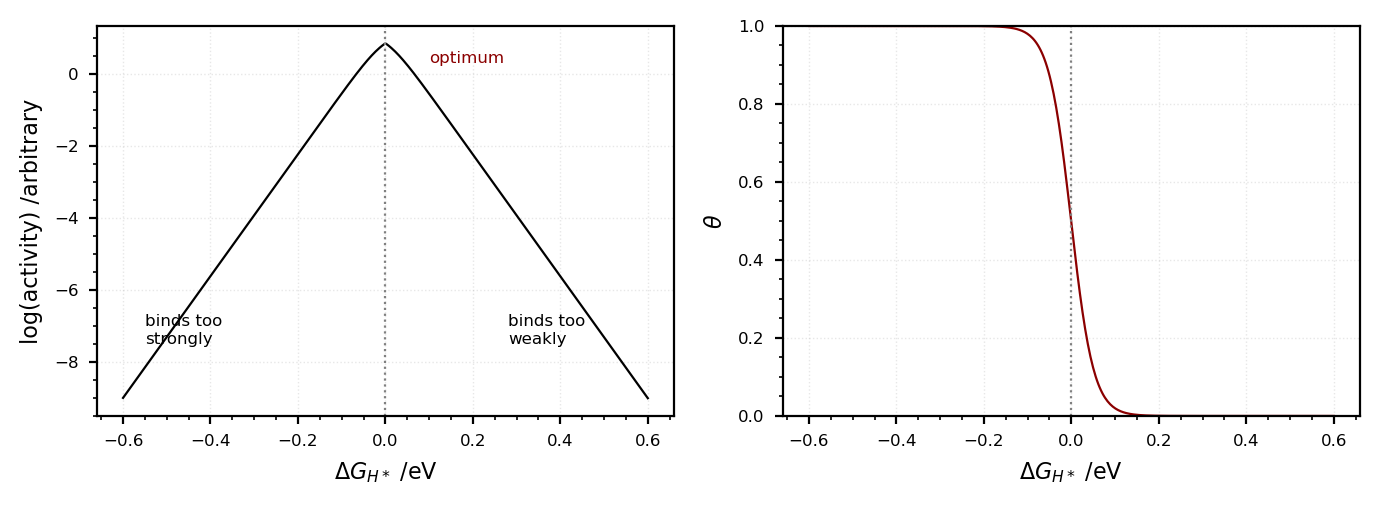

In [8]:
# The volcano is not a separate model.  It is Section 6, scanned along
# delta_g at fixed overpotential instead of along eta at fixed delta_g.
binding_energy = np.linspace(-0.6, 0.6, 400)      # eV, relative to the optimum
current, coverage = echem.her_microkinetic(-0.10, delta_g_ads=binding_energy)

fig = plt.figure(figsize=WIDE)
ax1 = plt.subplot(121)
ax2 = plt.subplot(122)

ax1.plot(binding_energy, np.log10(current), color='black')
ax1.axvline(0, linestyle=':', color='gray')
ax1.set_xlabel(r'$\Delta G_{H*}$ /eV')
ax1.set_ylabel(r'log(activity) /arbitrary')
ax1.annotate('binds too\nstrongly', (-0.55, -7.5), fontsize=6)
ax1.annotate('binds too\nweakly', (0.28, -7.5), fontsize=6)
ax1.annotate('optimum', (0.10, 0.3), fontsize=6, color='darkred')

ax2.plot(binding_energy, coverage, color='darkred')
ax2.axvline(0, linestyle=':', color='gray')
ax2.set_xlabel(r'$\Delta G_{H*}$ /eV')
ax2.set_ylabel(r'$\theta$')
ax2.set_ylim(0, 1)
fig.savefig('../Workspace/her-volcano.png')

The right-hand panel is the reason for the volcaon shape. It should look familiar because it is the coverage curve from Section 5, but now it is driven by binding energy instead of by applied potential. On the left branch the surface is saturated with H* and nothing can leave. On the right branch it is bare and nothing arrives.

**The volcano and the bending of Tafel plots to a new characteristic RDS are the same physics, viewed from two perspectives.**

This plot is often oversold.

Most volcano plots are built from computed binding energies, where the computations require assumptions about the functional system. More importantly, the branches of a volcano are only straight because of **scaling relations**, where $\Delta G^\ddagger \propto \Delta G ^\circ$. On most surfaces the binding energies of related intermediates are correlated with one another, at least while in a consistent reaction environment, so you cannot tune one without dragging the others along. Understanding that correlation and its limitations is the basis of a signficant portion of modern (electro)catalysis.

<div class="alert alert-block alert-warning">
<b>Project Idea:</b> Strategies for breaking scaling relations, whether through bifunctional sites, tethered relays or confinement, would make an excellent report topic. The claim is easy to state and hard to demonstrate, which makes for a good critical read.
</div>

#### Back to water oxidation

Water splitting pairs the 2-electron HER with the 4-electron oxygen evolution reaction (OER). The general approach described here is equally as applicable to such more complex systems, the math and number of potential branching patheways simply expand.

An **associative mechanism** runs through three adsorbed intermediates:

$ \large * \rightarrow OH* \rightarrow O* \rightarrow OOH* \rightarrow * + O_2 $

---
# Literature Examples

#### Mapping every possibility for one reaction

The complete enumeration of mechanisms and their expected slopes was done for oxygen evolution decades ago, and the paper is still worth reading for its thoroughness. The net outcome is the one we reached above: **the slope of a Tafel plot is not dictated by $\beta$ alone.**

[J. Phys. Chem. 1983, 87, 2960](https://doi.org/10.1021/j100238a048)

<img src='../Resources/images/bockris.png' width=50%>

#### Microkinetic analysis, done properly

Modern computing makes it straightforward to solve the full set of coupled elementary steps rather than assuming one of them is rate determining. The paper below works through the mathematics for several reactions relevant to energy storage, and it is a good template if you ever need to do this for your own system.

[Sci. Rep. 2015, 5, 13801](https://www.nature.com/articles/srep13801)

<img src='../Resources/images/scirep.png' width=40%>

This lesson is deliberately paired with **Discussion 5: Zone Diagrams**, where you will see the same idea, a reaction that changes character depending on which step controls it, mapped out across a full parameter space rather than reduced to a single slope.